# Model training and comparison

Stage 06 uses five versioned groups on one resource-ready cohort: R0 constant; R1 state/background; RB additional never-entered batting resources; RW additional remaining bowling resources; RBW both resource blocks. No standalone current-player quality or evidence is permitted. Target: first-innings batting team's final win, before each recorded event.

**Validation comparisons only. No test predictions, calibration fitting, resource extensions or NWC.** Separate innings models share a target, not guaranteed continuity.

Set `RUN_STAGE = True` only for an explicit full training run. Otherwise leave False to read verified saved results. Missing/stale outputs never start training automatically. Saved models use the `models/resource_sums_v2/` subdirectory.


In [1]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'config/model_comparison.json').is_file() and (p / 'src/model_comparison.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import model_comparison as stage
import model_comparison_visualisation as viz
from audit_visualisation import table
importlib.reload(stage)
importlib.reload(viz)
RUN_STAGE = False
SAVE_FIGURES = True
OUTPUT = ROOT / stage.REPORT_DIR
config = stage.read_config(ROOT)
print('Project:', ROOT)
print('Python:', sys.executable)
print('Candidate fits:', 4 * len(stage.ARMS) * sum(len(v) for v in config['candidate_grid'].values()), '+ 4 constants')
print('Stage 06 supplies per-group validation winners and RBW controls. Stage 08 selects each track across eight groups using validation Log Loss.')


Project: D:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe
Candidate fits: 192 + 4 constants
Stage 06 supplies per-group validation winners and RBW controls. Stage 08 selects each track across eight groups using validation Log Loss.


## 1. Check inputs, then train explicitly or verify results

Before any full training, the code checks exact feature allowlists, identical common match/event membership, complete-date chronological splits and absence of direct current-player quality/evidence. A preflight audit records event-key hashes for all arms. The existing frozen split must match.

Candidates are Logistic Regression, Random Forest, HistGradientBoosting and XGBoost, all compared in the same training loop and result tables. XGBoost uses three CPU histogram-tree configurations: 200 trees with (learning rate, max depth) of (0.05, 3), (0.1, 3), and (0.05, 6). Preprocessing and constant-column removal use training data only. HistGradientBoosting random early stopping remains disabled; XGBoost has no early stopping or validation eval_set. Convergence failure stops the run. No train-plus-validation refit is performed.


In [2]:
if RUN_STAGE:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
print('Verified experiment:', summary['experiment_id'])
print('Contract:', summary['contract_version'])
print('Matches:', summary['matches'], '| Events:', summary['events'])
print('Saved models:', summary['saved_family_models'], '| Test predictions:', summary['test_predictions'])
preflight = json.loads((OUTPUT / 'preflight_audit.json').read_text(encoding='utf-8'))
print('Preflight:', preflight['status'], '| No direct current quality:', preflight['no_current_player_direct_quality_or_evidence'])
figures = viz.build_figures(ROOT)
if SAVE_FIGURES:
    viz.save_figures(ROOT, summary, figures)
plt.close('all')


Verified experiment: 6e6900f138d2d126cde400922f163121d708f513b0af8e8b94c27f2b1d77ec77
Contract: resource_sums_v2
Matches: 1521 | Events: 360721
Saved models: 68 | Test predictions: 0
Preflight: passed | No direct current quality: True


## 2. Shared chronological split

Approximately 70/15/15 by match count within gender. Equal dates and both innings stay together. Boundaries use dates/counts, not outcomes. Test metadata are counted for coverage only. Existing splits cannot silently change on a rerun.


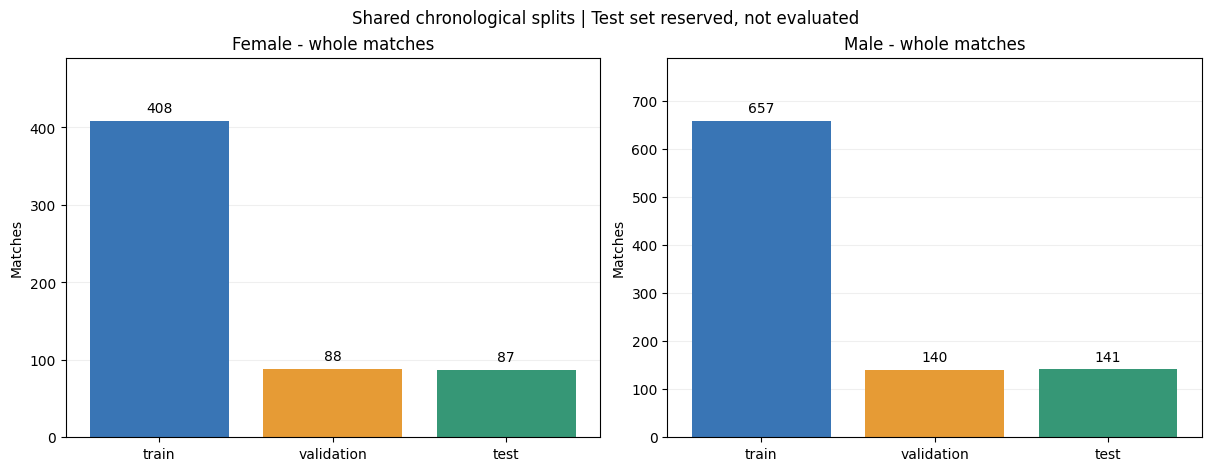

gender,split,matches,events,first_date,last_date
female,test,87,20609,2025-01-31,2026-08-04
female,train,408,95792,2009-06-18,2023-10-05
female,validation,88,20908,2023-10-14,2025-01-29
male,test,141,33241,2024-12-05,2026-07-26
male,train,657,156878,2005-02-17,2022-10-12
male,validation,140,33293,2022-10-13,2024-12-03


In [3]:
display(figures['split_counts.png'])
display(table(pd.read_csv(OUTPUT / 'split_summary.csv'), 'Whole-match chronological split'))


## 3. Five fair comparison groups

All four learned groups share the same state/background block. RB adds four batting-resource dimensions; RW adds three bowling-resource dimensions; RBW adds all seven. R0 uses only the training-event outcome prevalence. Capacity/history diagnostics are not additional predictors in one arm.

Resources are uncentered sums, not signed relative advantages. Standalone striker, non-striker and bowler quality plus associated evidence fields are excluded. The current bowler's quality can still enter its capacity-weighted resource; this is not statistical independence or causal attribution.

First-innings models omit chase-only fields; all tracks omit the constant innings indicator. Train-constant columns are logged.


In [4]:
groups = json.loads((OUTPUT / 'feature_groups.json').read_text(encoding='utf-8'))
display(table(pd.DataFrame([{'Group': viz.LABELS[a], 'Candidate columns before track omissions': len(cols)} for a, cols in groups['arms'].items()]), 'Prespecified feature groups'))
audit = json.loads((OUTPUT / 'preprocessing_audit.json').read_text(encoding='utf-8'))
display(table(pd.DataFrame([{'Track': r['track'], 'Group': stage.ARM_CODES[r['arm']], 'Algorithm': r['family'], 'Removed train constants': ', '.join(r['train_constant_columns_removed'])} for r in audit]), 'Training-only preprocessing audit'))


Group,Candidate columns before track omissions
R0: Constant,0
R1: State,16
RB: + Batting,20
RW: + Bowling,19
RBW: + Both,23


Track,Group,Algorithm,Removed train constants
female_innings_1,R1,logistic_regression,
female_innings_1,R1,random_forest,
female_innings_1,R1,hist_gradient_boosting,
female_innings_1,R1,xgboost,
female_innings_1,RB,logistic_regression,
female_innings_1,RB,random_forest,
female_innings_1,RB,hist_gradient_boosting,
female_innings_1,RB,xgboost,
female_innings_1,RW,logistic_regression,
female_innings_1,RW,random_forest,


## 4. Compare features within each algorithm

Lower validation log loss is better. Each cell uses that algorithm's best parameter configuration per feature group. This controls algorithm family, not every hyperparameter. Validation differences do not establish statistical significance.


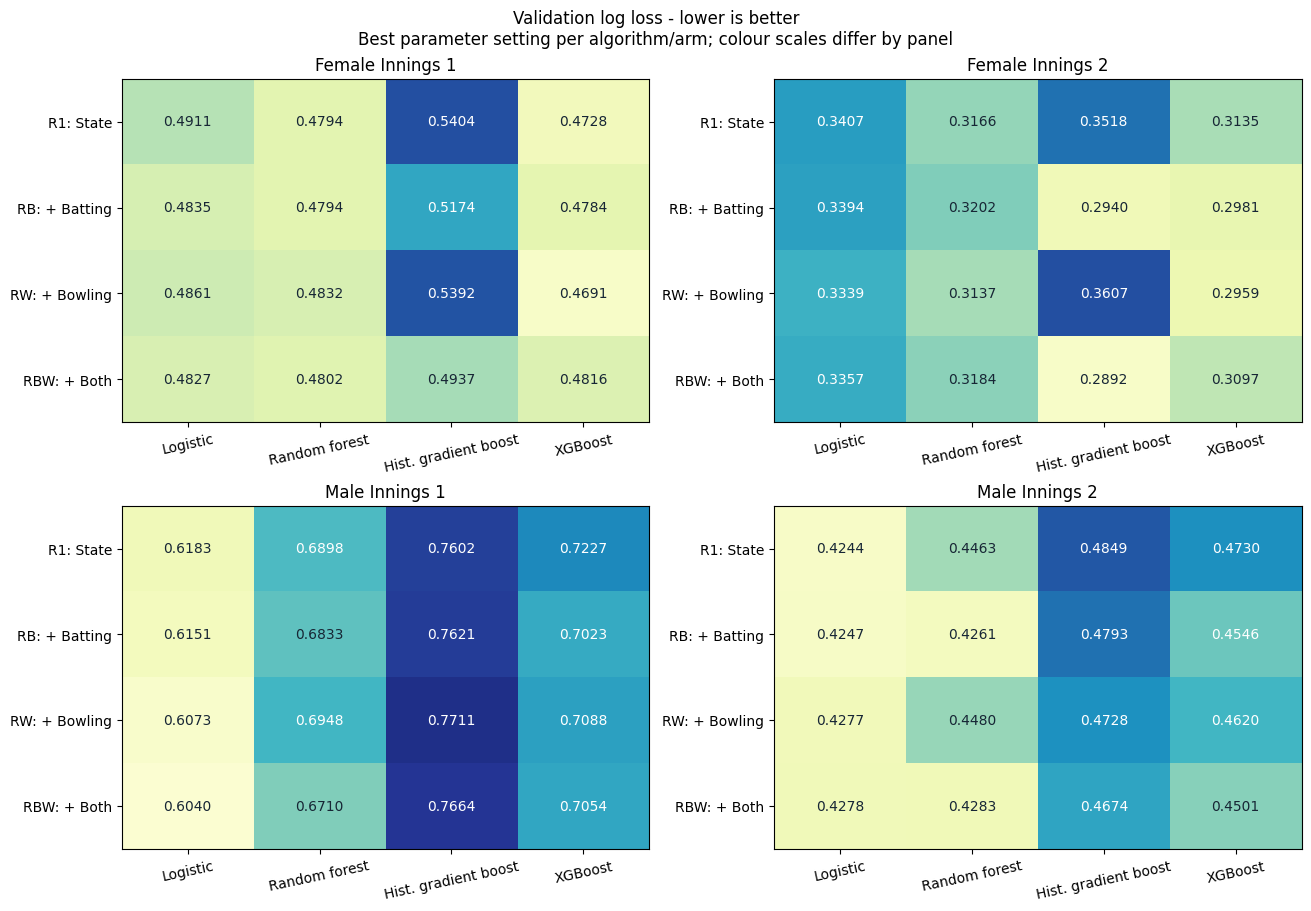

track,arm_code,family,candidate,validation_event_log_loss,validation_match_log_loss,validation_brier
female_innings_1,R0,constant,0,0.697703,0.697550,0.252272
female_innings_1,R1,logistic_regression,0,0.491125,0.487955,0.161280
female_innings_1,R1,random_forest,0,0.479394,0.477675,0.157952
female_innings_1,R1,hist_gradient_boosting,0,0.540400,0.540103,0.186849
female_innings_1,R1,xgboost,0,0.472773,0.470992,0.157695
female_innings_1,RB,logistic_regression,1,0.483484,0.480502,0.158477
female_innings_1,RB,random_forest,0,0.479382,0.477741,0.157423
female_innings_1,RB,hist_gradient_boosting,0,0.517402,0.517598,0.178618
female_innings_1,RB,xgboost,0,0.478442,0.476687,0.159170
female_innings_1,RW,logistic_regression,0,0.486108,0.483114,0.160583


In [5]:
display(figures['validation_family_heatmap.png'])
family_winners = pd.read_csv(OUTPUT / 'family_winners.csv')
display(table(family_winners[['track', 'arm_code', 'family', 'candidate', 'validation_event_log_loss', 'validation_match_log_loss', 'validation_brier']], 'Best configuration within each algorithm'))


## 5. Per-group selections and the RBW reference models

Within each feature group, select algorithm and parameters using validation event Log Loss only. Exact ties use a fixed family/grid order. Match-averaged losses, Brier score, accuracy and AUC are supplementary. R0 uses training-event prevalence, not Naive Bayes.

The four RBW models serve as shared resource controls in Stage 07. All five Stage 06 groups supply their within-group validation winners to Stage 08. Stage 08 combines them with IB, IW and IBW from Stage 07, includes RBW once, and selects each track's feature group, algorithm and parameters using validation event Log Loss. First-innings models omit chase-only fields.


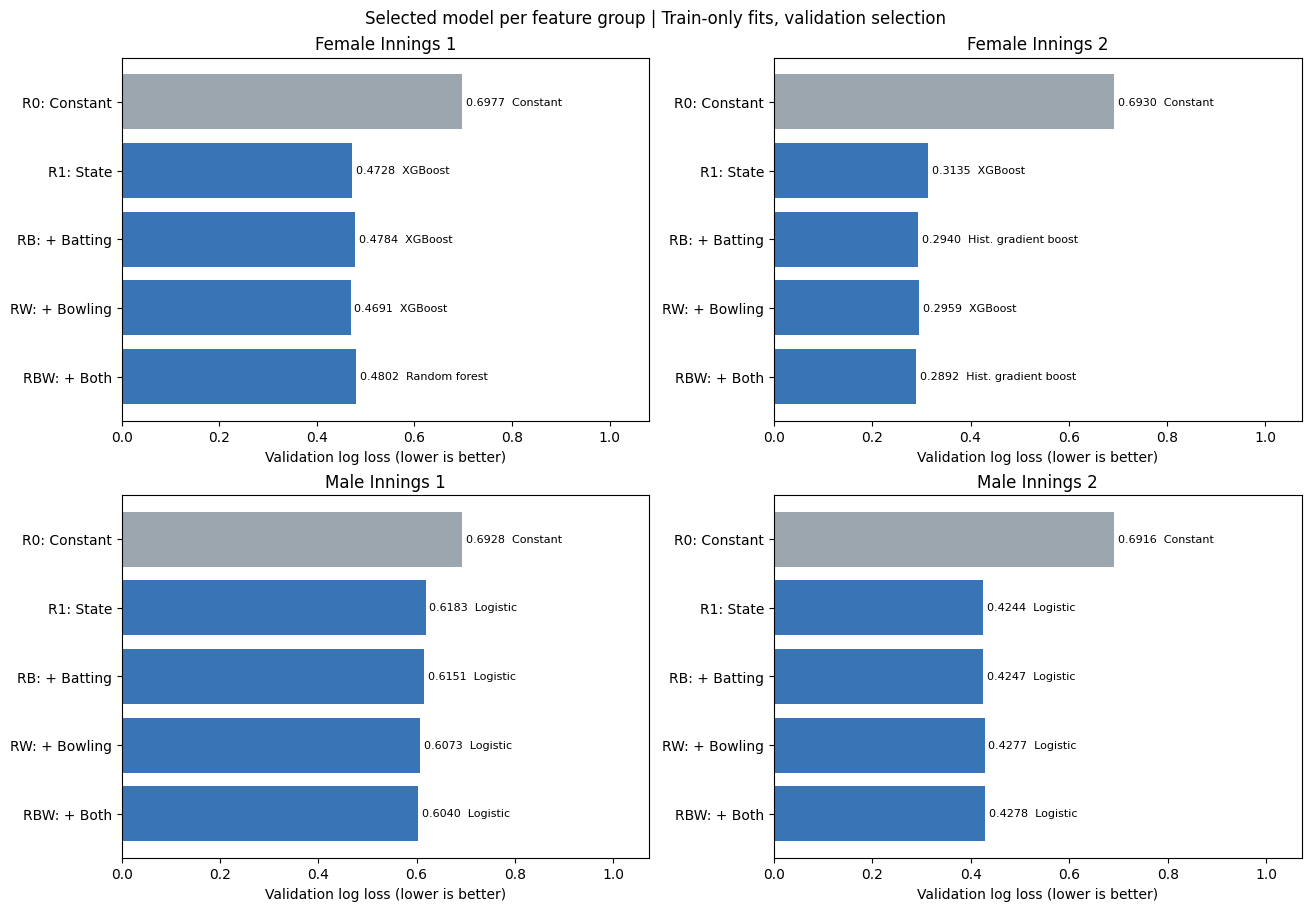

track,arm_code,family,validation_event_log_loss,validation_match_log_loss,validation_brier,validation_accuracy,validation_auc
female_innings_1,R0,constant,0.697703,0.697550,0.252272,0.487606,0.500000
female_innings_1,R1,xgboost,0.472773,0.470992,0.157695,0.757069,0.842000
female_innings_1,RB,xgboost,0.478442,0.476687,0.159170,0.752846,0.837550
female_innings_1,RW,xgboost,0.469121,0.467462,0.155499,0.759824,0.848229
female_innings_1,RBW,random_forest,0.480220,0.478973,0.158720,0.760007,0.842703
female_innings_2,R0,constant,0.692993,0.693106,0.249923,0.541234,0.500000
female_innings_2,R1,xgboost,0.313505,0.307206,0.101146,0.849241,0.937840
female_innings_2,RB,hist_gradient_boosting,0.294031,0.285907,0.091474,0.875200,0.947832
female_innings_2,RW,xgboost,0.295886,0.289738,0.094679,0.859824,0.945438
female_innings_2,RBW,hist_gradient_boosting,0.289184,0.281316,0.091928,0.866813,0.948641


track,arm_code,family,parameters,validation_event_log_loss
female_innings_1,RBW,random_forest,"{""max_depth"": 14, ""min_samples_leaf"": 50, ""n_estimators"": 200}",0.480220
female_innings_2,RBW,hist_gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 200, ""max_leaf_nodes"": 15}",0.289184
male_innings_1,RBW,logistic_regression,"{""C"": 0.01}",0.603961
male_innings_2,RBW,logistic_regression,"{""C"": 0.1}",0.427849


In [6]:
display(figures['selected_models.png'])
selected = pd.read_csv(OUTPUT / 'selected_models.csv')
display(table(selected[['track', 'arm_code', 'family', 'validation_event_log_loss', 'validation_match_log_loss', 'validation_brier', 'validation_accuracy', 'validation_auc']], 'Validation-selected models'))
display(table(pd.read_csv(OUTPUT / 'selected_systems.csv')[['track', 'arm_code', 'family', 'parameters', 'validation_event_log_loss']], 'RBW reference models for Stage 07: selected algorithm and parameters'))


### 5.1 Best validation result within Stage 06

This table summarises the best validation result among the five Stage 06 groups on identical events. Its tie rule uses family/candidate order followed by R0/R1/RB/RW/RBW order. Final selection takes place in Stage 08 across all eight Stage 06 and Stage 07 groups, using the declared Stage 08 tie rule. Every within-group winner is a candidate, regardless of its rank in this Stage 06 summary. Validation ranking alone does not establish test improvement or resource usefulness.


In [7]:
supplementary_best = stage.select_cross_group_best(selected)
supplementary_table = supplementary_best[['track', 'arm_code', 'arm', 'family', 'validation_event_log_loss']].copy()
supplementary_table['arm'] = supplementary_table['arm'].map(viz.LABELS)
supplementary_table['Same group as Stage 06 RBW reference'] = supplementary_best['arm'].eq(stage.PREFERRED_ARM).map({True: 'Yes', False: 'No'})
supplementary_table = supplementary_table.rename(columns={'track': 'Track', 'arm_code': 'Group', 'arm': 'Inputs', 'family': 'Algorithm', 'validation_event_log_loss': 'Validation log loss'})
display(table(supplementary_table, 'Supplementary cross-group winners - display only, not NWC model selection'))


Track,Group,Inputs,Algorithm,Validation log loss,Same group as Stage 06 RBW reference
female_innings_1,RW,RW: + Bowling,xgboost,0.469121,No
female_innings_2,RBW,RBW: + Both,hist_gradient_boosting,0.289184,Yes
male_innings_1,RBW,RBW: + Both,logistic_regression,0.603961,Yes
male_innings_2,R1,R1: State,logistic_regression,0.424383,No


## 6. Do resource features improve validation predictions?

Gain = reference log loss minus treatment log loss; positive is improvement. Compare RB/R1, RW/R1 and RBW/R1. Also compare RBW/RW and RBW/RB to separate the incremental value of each resource block. These are prespecified comparisons, not new groups.

Within-family comparisons still tune each arm's hyperparameters. The `selected_system` comparison label means each compared arm chooses its own algorithm; it does not itself select the final downstream model. The Stage 06 `selected_systems.csv` registry supplies RBW controls to Stage 07. Stage 08 selects final models by validation Log Loss across the eight unique groups and reports all groups in the test comparison. Report all comparisons, including worse performance. Neither comparison establishes a causal feature effect or statistically significant test-set improvement.


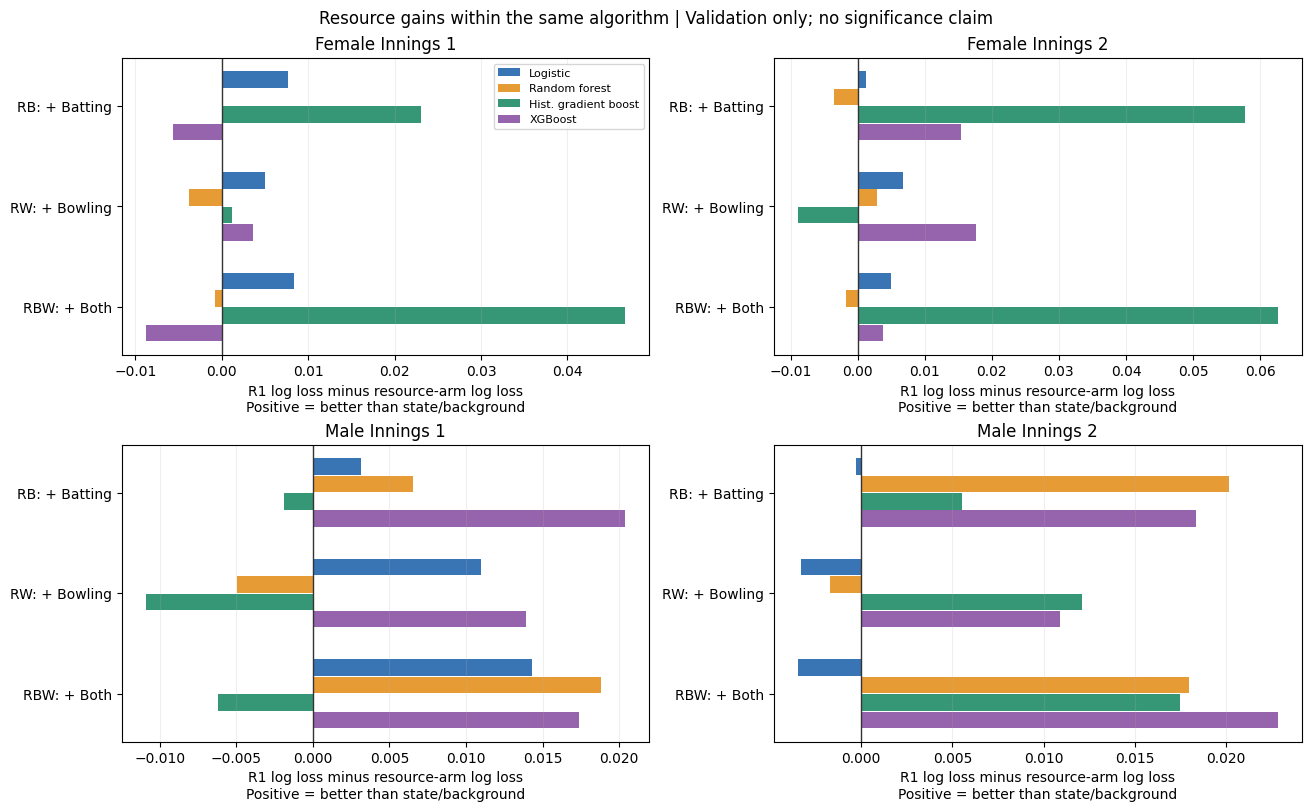

view,track,treatment,reference,treatment_family,reference_family,validation_log_loss_gain,validation_brier_gain
selected_system,female_innings_1,batting_resources,state,xgboost,xgboost,-0.005669,-0.001475
selected_system,female_innings_1,bowling_resources,state,xgboost,xgboost,0.003652,0.002196
selected_system,female_innings_1,both_resources,state,random_forest,xgboost,-0.007447,-0.001025
selected_system,female_innings_1,both_resources,bowling_resources,random_forest,xgboost,-0.011099,-0.003221
selected_system,female_innings_1,both_resources,batting_resources,random_forest,xgboost,-0.001778,0.000450
selected_system,female_innings_2,batting_resources,state,hist_gradient_boosting,xgboost,0.019474,0.009672
selected_system,female_innings_2,bowling_resources,state,xgboost,xgboost,0.017620,0.006468
selected_system,female_innings_2,both_resources,state,hist_gradient_boosting,xgboost,0.024321,0.009218
selected_system,female_innings_2,both_resources,bowling_resources,hist_gradient_boosting,xgboost,0.006702,0.002750
selected_system,female_innings_2,both_resources,batting_resources,hist_gradient_boosting,hist_gradient_boosting,0.004847,-0.000454


view,track,treatment,reference,treatment_family,reference_family,validation_log_loss_gain,validation_brier_gain
within_family,female_innings_1,both_resources,bowling_resources,logistic_regression,logistic_regression,0.003364,0.001526
within_family,female_innings_1,both_resources,batting_resources,logistic_regression,logistic_regression,0.000740,-0.000580
within_family,female_innings_1,both_resources,bowling_resources,random_forest,random_forest,0.003004,0.001311
within_family,female_innings_1,both_resources,batting_resources,random_forest,random_forest,-0.000838,-0.001297
within_family,female_innings_1,both_resources,bowling_resources,hist_gradient_boosting,hist_gradient_boosting,0.045545,0.017726
within_family,female_innings_1,both_resources,batting_resources,hist_gradient_boosting,hist_gradient_boosting,0.023710,0.010004
within_family,female_innings_1,both_resources,bowling_resources,xgboost,xgboost,-0.012465,-0.004631
within_family,female_innings_1,both_resources,batting_resources,xgboost,xgboost,-0.003144,-0.000960
within_family,female_innings_2,both_resources,bowling_resources,logistic_regression,logistic_regression,-0.001796,-0.000635
within_family,female_innings_2,both_resources,batting_resources,logistic_regression,logistic_regression,0.003738,0.001029


In [8]:
display(figures['resource_validation_gains.png'])
deltas = pd.read_csv(OUTPUT / 'validation_deltas.csv')
display(table(deltas[deltas['view'].eq('selected_system')], 'Validation gains between groups, each with its own selected algorithm'))
display(table(deltas[deltas.reference.isin(['batting_resources', 'bowling_resources'])], 'Incremental contribution of the second resource block'))


In [9]:
for item in summary['limitations']:
    print('-', item)
print('Model/report directory:', OUTPUT)
print('Split and validation predictions:', ROOT / stage.DATA_DIR)


- Conservative resource-ready cohort; review matches excluded identically from all arms.
- Previously inspected historical matches are not a new untouched confirmatory test set.
- Separate innings models share a target but need not be continuous across the innings break.
- Within-family comparisons tune each arm; not a pure fixed-hyperparameter feature effect.
- No post-hoc calibration fitted. Log loss/Brier improvements are not pure calibration improvements.
Model/report directory: D:\T20_Project\T20_Project_3.0\outputs\06_model_training_and_comparison
Split and validation predictions: D:\T20_Project\T20_Project_3.0\data\processed\model_comparison
